# Нейросетевые методы NNF и NNFA обнаружения структурных выбросов: программный код отчёта

Код, по которому получены результаты отчёта "Нейросетевые методы NNF и NNFA обнаружения структурных выбросов:
проверка на трёх наборах данных и влияние очистки на объём обучающей выборки". Разделы идут в том же порядке,
что в отчёте; для каждого раздела приведён код постановки и вывод таблиц и рисунков отчёта.

Долгие расчёты по умолчанию не повторяются: при `RECOMPUTE = False` таблицы результатов берутся из
`Код_и_результаты/results` и `Очистка_и_объём_выборки/results`. При `RECOMPUTE = True` все эксперименты
пересчитываются этим же кодом (около 8 ч на двух ядрах).

In [1]:
RECOMPUTE = False     # True: пересчитать все эксперименты заново
N_JOBS = -1           # число параллельных процессов, -1: все ядра

import os, sys, math, time, warnings
os.environ.setdefault("OMP_NUM_THREADS", "1")       # параллелизм через joblib, без потоков BLAS
from dataclasses import dataclass, field
from pathlib import Path
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy.stats import norm, wilcoxon
from sklearn.datasets import make_friedman1
from sklearn.metrics import roc_auc_score
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from IPython.display import Image, display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)

ROOT = Path.cwd()                                   # папка с кодом и результатами
if not (ROOT / "src").exists():
    ROOT = ROOT / "Код_и_результаты"
RES = ROOT / "results"
SS_RES = ROOT.parent / "Очистка_и_объём_выборки" / "results"
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "report")]

# из модулей проекта берутся только классические методы (PyOD, scikit-learn) и оформление
from baselines import classical_scores, CLASSICAL_METHODS, CONTROL, RF_OOB
from stats import c, holm                           # число с десятичной запятой; поправка Холма


def table(name, jobs, fn, folder=RES):
    """Таблица результатов: загрузка сохранённой или расчёт по списку заданий."""
    path = folder / name
    if RECOMPUTE or not path.exists():
        out = Parallel(n_jobs=N_JOBS)(delayed(fn)(*j) for j in jobs)
        rows = [r for o in out for r in (o if isinstance(o, list) else [o])]
        pd.DataFrame(rows).to_csv(path, index=False)
    return pd.read_csv(path)

## 1. Данные и структурные выбросы

Три набора по 1030 наблюдений: Concrete Compressive Strength, подвыборка California Housing и функция
Фридмана № 1 (шум N(0; 1), входы 6–10 на *y* не влияют). Структурный выброс мощности *k*: значение *y* сдвигается
на *k*σ<sub>y</sub> к медиане и остаётся внутри диапазона *y*, поэтому выброс нарушает только связь *y* с входами.

In [2]:
def load_dataset(name):
    """Concrete: исходный файл; California и Фридман: подготовленные выборки по 1030 наблюдений
    (как они получены из исходных данных, см. src/datasets.py)."""
    if name == "concrete":
        d = pd.read_csv(ROOT / "data" / "concrete.csv")
        return d.iloc[:, :8].to_numpy(float), d["strength"].to_numpy(float)
    d = pd.read_csv(ROOT / "data" / f"{name}_1030.csv")
    return d.iloc[:, :-1].to_numpy(float), d.iloc[:, -1].to_numpy(float)


DS = {"concrete": "Concrete", "california": "California", "friedman": "Фридман"}
DATA = {d: load_dataset(d) for d in DS}

# Таблица 1
pd.DataFrame({DS[d]: {"объём": len(y), "входов": X.shape[1], "σy": c(y.std())}
              for d, (X, y) in DATA.items()}).T

,объём,входов,σy
Concrete,1030,8,"16,70"
California,1030,8,"1,14"
Фридман,1030,10,"4,87"


In [3]:
def inject_y_outliers(y, n_out, k_sigma, rng, mode="isolated", X=None):
    """n_out структурных выбросов мощностью k_sigma·σy.
    isolated: случайные наблюдения; cluster: n_out ближайших соседей по входам со сдвигом в одну сторону."""
    y = np.asarray(y, float).copy()
    sigma = y.std()
    signs = -np.sign(y - np.median(y))                       # сдвиг к центру распределения
    signs[signs == 0] = 1.0
    y_new = y + signs * k_sigma * sigma
    cand = np.flatnonzero((y_new >= y.min()) & (y_new <= y.max()))   # значение остаётся в диапазоне y
    if mode == "isolated":
        idx = rng.choice(cand, size=n_out, replace=False)
    else:
        Xs = (X - X.mean(0)) / X.std(0)
        center = int(rng.choice(cand))
        same = cand[signs[cand] == signs[center]]
        idx = same[np.argsort(np.linalg.norm(Xs[same] - Xs[center], axis=1))[:n_out]]
    y[idx] = y[idx] + signs[idx] * k_sigma * sigma
    truth = np.zeros(len(y), dtype=int)
    truth[idx] = 1
    return y, truth


def inject_preprint_scenario(y, n_out):
    """Постановка препринта: n_out/2 наибольших и n_out/2 наименьших значений y заменяются на (max + min)/2."""
    y = np.asarray(y, float).copy()
    order = np.argsort(y)
    idx = np.concatenate([order[:n_out // 2], order[-(n_out // 2):]])
    y[idx] = (y.max() + y.min()) / 2
    truth = np.zeros(len(y), dtype=int)
    truth[idx] = 1
    return y, truth

## 2. Методы NNF и NNFA

Сеть Linear → Tanh → Linear обучается на всей выборке (Adam, lr = 0,01, 500 эпох, полный батч); оценка
наблюдения равна квадрату его ошибки обучения. NNF: одна сеть с *N* = ⌈*N*<sub>min</sub>⌉. NNFA: среднее оценок
по сетям с *N* от *N*<sub>min</sub> до *N*<sub>min</sub> + ξ(*N*<sub>max</sub> − *N*<sub>min</sub>), где
[*N*<sub>min</sub>; *N*<sub>max</sub>] — интервал АКХН с поправками из кода авторов. Код авторов перенесён
с PyTorch на NumPy; при одинаковых начальных весах ошибки обучения совпадают до 1e-15 (`src/verify.py`).

In [4]:
def akhn_bounds(Q, N_x, N_y=1):
    """Интервал АКХН в варианте кода авторов (+1 к Nmin, −1 к Nmax, страховка при Nmax > Q)."""
    log2q = math.log2(Q)
    n_min = (N_y * Q) / ((1 + log2q) * (N_x + N_y)) + 1
    n_max = (N_y / (N_x + N_y)) * ((Q / N_x + 1) * (N_x + N_y + 1) + 1) - 1
    if n_max > Q:
        n_max = min(Q // 2, 20)
    return n_min, n_max


def n_range(Q, N_x, N_y=1, xi=0.0):
    """Числа нейронов сетей ансамбля: xi = 0 — одна сеть (NNF), xi > 0 — NNFA."""
    n_min, n_max = akhn_bounds(Q, N_x, N_y)
    n_lim = n_min + xi * (n_max - n_min)
    start = max(1, int(np.ceil(n_min)))
    return list(range(start, max(start, int(np.ceil(n_lim))) + 1))


@dataclass
class Adam:
    lr: float = 0.01
    b1: float = 0.9
    b2: float = 0.999
    eps: float = 1e-8
    t: int = 0
    m: dict = field(default_factory=dict)
    v: dict = field(default_factory=dict)

    def step(self, params, grads):
        self.t += 1
        bc1, bc2 = 1 - self.b1 ** self.t, 1 - self.b2 ** self.t
        for i, (p, g) in enumerate(zip(params, grads)):
            if i not in self.m:
                self.m[i], self.v[i] = np.zeros_like(p), np.zeros_like(p)
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * g
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * (g * g)
            p -= self.lr * (self.m[i] / bc1) / (np.sqrt(self.v[i] / bc2) + self.eps)


@dataclass
class Rprop:
    """Как torch.optim.Rprop: им в препринте получены рисунки пригодности сети (раздел 3)."""
    lr: float = 0.01
    prev: dict = field(default_factory=dict)
    size: dict = field(default_factory=dict)

    def step(self, params, grads):
        for i, (p, g) in enumerate(zip(params, grads)):
            if i not in self.prev:
                self.prev[i], self.size[i] = np.zeros_like(p), np.full_like(p, self.lr)
            sign = np.sign(g * self.prev[i])
            factor = np.where(sign > 0, 1.2, np.where(sign < 0, 0.5, 1.0))
            self.size[i] = np.clip(self.size[i] * factor, 1e-6, 50.0)
            g = np.where(sign < 0, 0.0, g)
            p -= np.sign(g) * self.size[i]
            self.prev[i] = g


def linear_init(rng, fan_in, fan_out):
    """Начальные веса как в torch.nn.Linear: U(−1/√fan_in, 1/√fan_in)."""
    k = 1.0 / math.sqrt(fan_in)
    return rng.uniform(-k, k, size=(fan_in, fan_out)), rng.uniform(-k, k, size=(fan_out,))


def train_mlp_errors(X, y, n_hidden, epochs=500, lr=0.01, rng=None, optimizer="adam"):
    """Обучает сеть на всей выборке и возвращает квадраты ошибок обучения наблюдений."""
    rng = rng or np.random.default_rng(0)
    W1, b1 = linear_init(rng, X.shape[1], max(int(n_hidden), 1))
    W2, b2 = linear_init(rng, max(int(n_hidden), 1), 1)
    opt = Adam(lr=lr) if optimizer == "adam" else Rprop(lr=lr)
    yv = y.reshape(-1, 1)
    for _ in range(epochs):
        a1 = np.tanh(X @ W1 + b1)
        g_out = (2.0 / len(y)) * (a1 @ W2 + b2 - yv)            # производная MSE
        g_z1 = (g_out @ W2.T) * (1.0 - a1 * a1)
        opt.step([W1, b1, W2, b2], [X.T @ g_z1, g_z1.sum(0), a1.T @ g_out, g_out.sum(0)])
    return ((np.tanh(X @ W1 + b1) @ W2 + b2 - yv) ** 2).ravel()


def scale_minus1_1(a):
    a = np.asarray(a, float)
    lo, hi = a.min(axis=0), a.max(axis=0)
    return 2.0 * (a - lo) / np.where(hi > lo, hi - lo, 1.0) - 1.0


def nnfa_scores(X, y, xi=0.0, seed=0, y_range=None, units="scaled"):
    """Оценки NNF (xi = 0) и NNFA (xi > 0): средний по ансамблю квадрат ошибки обучения.
    y_range фиксирует шкалу y (нужно при последовательном удалении); units="original" — в единицах y."""
    X, y = np.asarray(X, float), np.asarray(y, float).ravel()
    lo, hi = (y.min(), y.max()) if y_range is None else y_range
    half = (hi - lo) / 2 if hi > lo else 1.0
    Xs, ys = scale_minus1_1(X), (y - lo) / half - 1.0             # входы и выход в [−1; 1]
    rng = np.random.default_rng(seed)
    errors = np.array([train_mlp_errors(Xs, ys, N, rng=rng) for N in n_range(len(y), X.shape[1], 1, xi)])
    if units == "original":
        errors = errors * half ** 2
    return errors.mean(axis=0)


def top_k_flags(scores, k):
    pred = np.zeros(len(scores), dtype=int)
    if k > 0:
        pred[np.argsort(scores)[-k:]] = 1
    return pred


def prf(pred_idx, truth):
    """Точность, полнота и F1 для множества объявленных выбросов."""
    pred = np.zeros(len(truth), int)
    pred[list(pred_idx)] = 1
    tp = int((pred & truth).sum())
    p = tp / pred.sum() if pred.sum() else 0.0
    r = tp / truth.sum() if truth.sum() else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)


def evaluate(scores, truth):
    """F1 при отборе m наблюдений с наибольшей оценкой (m известно) и ROC-AUC."""
    scores = np.asarray(scores, float)
    f1 = prf(np.flatnonzero(top_k_flags(scores, int(truth.sum()))), truth)[2]
    return f1, (0.5 if np.ptp(scores) == 0 else float(roc_auc_score(truth, scores)))


NNF, NNFA = "NNF (ξ=0)", "NNFA (ξ=0,1)"
X, y0 = DATA["concrete"]
print("Concrete: NNF —", n_range(1030, 8, 1, 0.0), "нейронов; NNFA (ξ = 0,1) —", n_range(1030, 8, 1, 0.1))

Concrete: NNF — [12] нейронов; NNFA (ξ = 0,1) — [12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]


**Сверка с препринтом.** В постановке препринта (20 крайних значений прочности заменены полусуммой минимума и
максимума) 30 повторов NNF сравниваются с опубликованным F1 = 0,760 и с кодом авторов (`src/exp1c_authors_code.py`,
PyTorch), запущенным на тех же данных.

In [5]:
def score_all(X, y, truth, run, methods=CLASSICAL_METHODS + [CONTROL]):
    """NNF, NNFA и классические методы на одних и тех же данных."""
    out = [(label, *evaluate(nnfa_scores(X, y, xi=xi, seed=run), truth)) for xi, label in [(0.0, NNF), (0.1, NNFA)]]
    out += [(name, *evaluate(s, truth)) for name, s in classical_scores(X, y, seed=run, methods=methods).items()]
    return out


def run_anchor(run):
    X, y0 = DATA["concrete"]
    y, truth = inject_preprint_scenario(y0, 20)
    return [dict(run=run, method=m, f1=f1, auc=auc) for m, f1, auc in score_all(X, y, truth, run)]


anchor = table("exp1_anchor.csv", [(r,) for r in range(30)], run_anchor)
authors = pd.read_csv(RES / "exp1c_authors_code.csv")
pd.DataFrame({"F1": [c(anchor[anchor.method == NNF].f1.mean(), 3), c(authors.f1.mean(), 3), "0,760"],
              "ст. ошибка": [c(anchor[anchor.method == NNF].f1.sem(), 3), c(authors.f1.sem(), 3), ""]},
             index=["NNF, перенос на NumPy", "код авторов (PyTorch)", "опубликовано в препринте"])

,F1,ст. ошибка
"NNF, перенос на NumPy","0,755","0,006"
код авторов (PyTorch),"0,760","0,009"
опубликовано в препринте,"0,760",


**Выбор ξ.** Качество и время NNFA при разных ξ на Concrete (2 % выбросов мощностью 2σ<sub>y</sub>, 10 повторов).

In [6]:
def run_xi(xi, run):
    X, y0 = DATA["concrete"]
    y, truth = inject_y_outliers(y0, 21, 2.0, np.random.default_rng(42_000 + run))
    t0 = time.perf_counter()
    f1, auc = evaluate(nnfa_scores(X, y, xi=xi, seed=run), truth)
    return dict(xi=xi, run=run, n_nets=len(n_range(len(y), X.shape[1], 1, xi)), f1=f1, auc=auc,
                seconds=time.perf_counter() - t0)


xi_tab = table("exp3b_xi_sensitivity.csv", [(xi, r) for xi in [0.0, 0.05, 0.1, 0.25, 0.5, 1.0] for r in range(10)], run_xi)
(xi_tab.groupby("xi")[["n_nets", "f1", "seconds"]].mean().round(3)
       .rename(columns={"n_nets": "сетей", "f1": "F1", "seconds": "время, с"}))

,сетей,F1,"время, с"
xi,,,
0.00,1.0,0.881,0.110
0.05,7.0,0.895,0.856
0.10,14.0,0.900,2.062
0.25,34.0,0.900,6.644
0.50,67.0,0.910,18.814
1.00,133.0,0.919,64.844


## 3. Устойчивость одиночной сети к выбору числа нейронов

Набор авторов из ноутбука `!!!_8` (гиперболический параболоид, 45 точек, один выброс). Сеть пригодна при
данном *N*, если ставит выброс на первое место хотя бы в 5 из 10 запусков. Сравниваются RPROP и Adam при 500
и 1000 эпохах.

In [7]:
def hyperbolic_paraboloid():
    """Сетка 21×21 на [−1; 1]², y = x1² − x2², выброс y = 0,45 в (0; 0), удалено 90 % обычных точек (seed авторов)."""
    g = np.arange(-1.0, 1.05, 0.1)
    X1, X2 = np.meshgrid(g, g)
    Y = X1 ** 2 - X2 ** 2
    mask = (np.abs(X1) < 1e-10) & (np.abs(X2) < 1e-10)
    Y[mask] = 0.45
    pts = np.column_stack([X1.ravel(), X2.ravel(), Y.ravel()])
    normal = np.flatnonzero(~mask.ravel())
    keep = np.ones(len(pts), bool)
    keep[np.random.RandomState(42).choice(normal, size=int(0.9 * len(normal)), replace=False)] = False
    return pts[keep][:, :2], pts[keep][:, 2], int(np.flatnonzero(mask.ravel()[keep])[0])


def run_optimizer(config, opt, epochs, N, run):
    X, y, i_out = hyperbolic_paraboloid()
    err = train_mlp_errors(scale_minus1_1(X), scale_minus1_1(y.reshape(-1, 1)).ravel(), N, epochs=epochs,
                           rng=np.random.default_rng(42 + run), optimizer=opt)
    return dict(config=config, N=N, run=run, hit_top1=int(np.argmax(err) == i_out))


CONFIGS = [("Rprop, 500 эпох", "rprop", 500), ("Rprop, 1000 эпох", "rprop", 1000),
           ("Adam, 500 эпох", "adam", 500), ("Adam, 1000 эпох", "adam", 1000)]
opt_tab = table("exp3g_optimizer.csv", [(*cf, N, r) for cf in CONFIGS for N in range(1, 81) for r in range(10)],
                run_optimizer)
share = opt_tab.groupby(["config", "N"]).hit_top1.mean().ge(0.5).groupby(level="config").mean().mul(100).round()
share.reindex([cf[0] for cf in CONFIGS]).rename("доля пригодных N из 1–80, %").to_frame()

,"доля пригодных N из 1–80, %"
config,
"Rprop, 500 эпох",81.0
"Rprop, 1000 эпох",20.0
"Adam, 500 эпох",98.0
"Adam, 1000 эпох",98.0


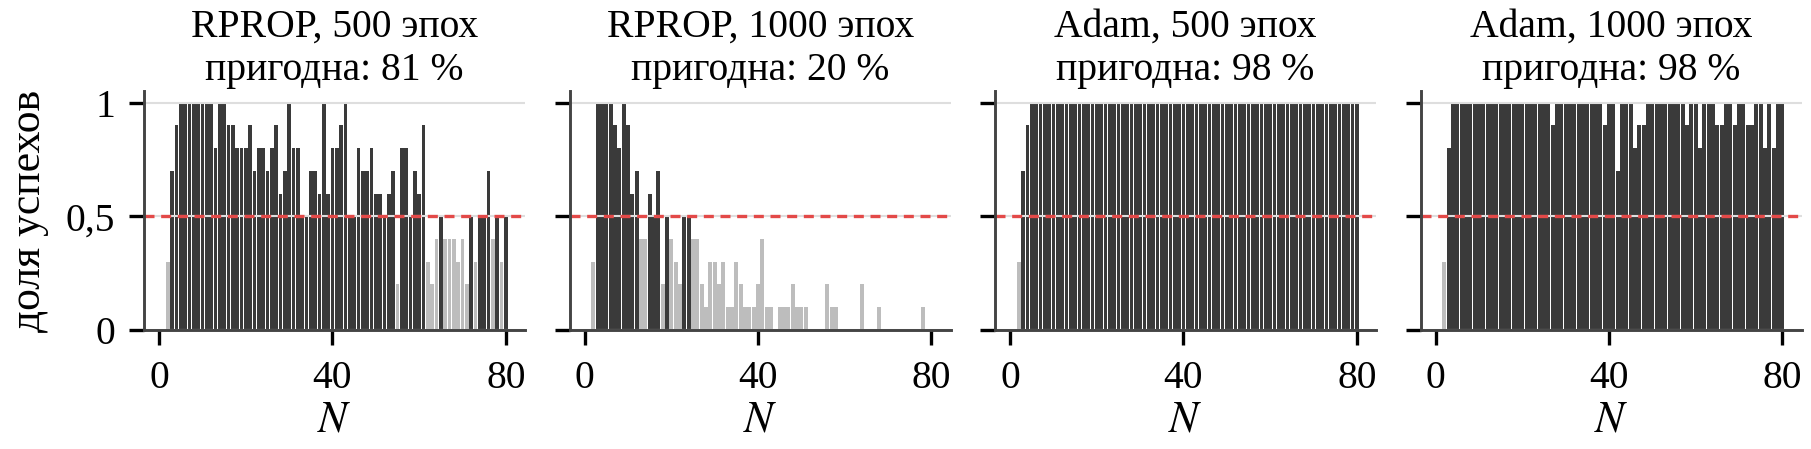

In [8]:
import paper_figures as PF                 # оформление рисунков отчёта
display(Image(str(PF.fig_optimizer()), width=900))   # рисунок 1

Одиночная сеть на Concrete (2 % выбросов мощностью 2σ<sub>y</sub>, Adam, 500 эпох) при *N* от 2 до 260,
в том числе за пределами интервала АКХН.

In [9]:
def run_n_scan(N, run):
    X, y0 = DATA["concrete"]
    y, truth = inject_y_outliers(y0, 21, 2.0, np.random.default_rng(55_000 + run))
    err = train_mlp_errors(scale_minus1_1(X), scale_minus1_1(y.reshape(-1, 1)).ravel(), N,
                           rng=np.random.default_rng(900 + run))
    f1, auc = evaluate(err, truth)
    return dict(N=N, run=run, f1=f1, auc=auc)


N_GRID = [2, 3, 4, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60, 80, 100, 120, 144, 170, 200, 260]
scan = table("exp3c_n_scan.csv", [(N, r) for N in N_GRID for r in range(15)], run_n_scan)
f1_N = scan.groupby("N").f1.mean()
print(f"F1 при N = 2…260: от {c(f1_N.min())} до {c(f1_N.max())}")

F1 при N = 2…260: от 0,78 до 0,92


## 4. Зависимость качества обнаружения от мощности выбросов

2 % выбросов (21 наблюдение), мощность *k* = 0,25…3σ<sub>y</sub>, 30 повторов на каждую точку. Все методы
в повторе получают одни и те же данные и отбирают *m* наблюдений с наибольшей оценкой. Порог обнаружимости
*k*\* — мощность, при которой средний F1 равен 0,5; его 95 %-й интервал строится бутстрепом по повторам.

In [10]:
K_VALUES = [0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0]


def run_magnitude(k, run, ds="concrete"):
    X, y0 = DATA[ds]
    rng = np.random.default_rng(10_000 * run + int(round(k * 100)))
    y, truth = inject_y_outliers(y0, int(round(0.02 * len(y0))), k, rng)
    return [dict(k_sigma=k, run=run, method=m, f1=f1, auc=auc) for m, f1, auc in score_all(X, y, truth, run)]


def result_name(ds, kind):
    concrete = {"magnitude": "exp1_magnitude.csv", "peeling": "exp2_peeling.csv",
                "trajectories": "exp2_trajectories.csv", "downstream": "exp3e_downstream.csv"}
    return concrete[kind] if ds == "concrete" else f"exp5_{ds}_{kind}.csv"


MAG = {ds: table(result_name(ds, "magnitude"), [(k, r, ds) for k in K_VALUES for r in range(30)], run_magnitude)
       for ds in DS}

In [11]:
# контрольный пересчёт: повтор 0 при k = 2 на Concrete этим кодом совпадает с сохранённой таблицей
check = pd.DataFrame(run_magnitude(2.0, 0)).set_index("method")[["f1", "auc"]]
saved = MAG["concrete"].query("k_sigma == 2.0 and run == 0").set_index("method")[["f1", "auc"]]
print("совпадает с results/exp1_magnitude.csv:", np.allclose(check.loc[saved.index], saved, atol=1e-12))

совпадает с results/exp1_magnitude.csv: True


In [12]:
def k_star(d):
    """Мощность, при которой средний F1 впервые достигает 0,5 (линейная интерполяция); nan — не достигается."""
    g = d.groupby("k_sigma").f1.mean().sort_index()
    k, f = g.index.values, g.values
    above = np.flatnonzero(f >= 0.5)
    if not len(above):
        return np.nan
    j = above[0]
    return float(k[0]) if j == 0 else float(k[j - 1] + (0.5 - f[j - 1]) * (k[j] - k[j - 1]) / (f[j] - f[j - 1]))


def k_star_ci(d, n_boot=2000, seed=0):
    """95 %-й бутстреп-интервал порога по повторам."""
    rng = np.random.default_rng(seed)
    piv = d.pivot_table(index="run", columns="k_sigma", values="f1")
    vals = []
    for _ in range(n_boot):
        m = piv.loc[rng.choice(piv.index, size=len(piv), replace=True)].mean()
        vals.append(k_star(pd.DataFrame({"k_sigma": m.index, "f1": m.values})))
    vals = np.array(vals)[np.isfinite(vals)]
    return np.percentile(vals, 2.5), np.percentile(vals, 97.5)


GROUPS = {
    "Нейросетевые фильтры": {NNFA: "NNFA (ξ = 0,1)", NNF: "NNF (ξ = 0)"},
    "Методы с моделью y(X)": {RF_OOB: "случайный лес, OOB-ошибка", "Random Forest (error)": "случайный лес, ошибка обучения",
                              "Neural Network (error)": "персептрон (20, 10)", "Combined (RF+AE)": "лес + автокодировщик"},
    "Методы без модели, по признакам X и y": {"LOF (with y)": "LOF (X, y)", "One-Class SVM (with y)": "One-Class SVM (X, y)",
                                              "Isolation Forest (with y)": "Isolation Forest (X, y)"},
    "Методы без модели, только по признакам X": {
        "Autoencoder (reconstruction)": "автокодировщик", "ABOD (pyod)": "ABOD", "COPOD (pyod)": "COPOD",
        "HBOS (pyod)": "HBOS", "IsolationForest (pyod)": "Isolation Forest (X)", "kNN (pyod)": "kNN",
        "LOF (pyod)": "LOF (X)", "OCSVM (pyod)": "One-Class SVM (X)", "PCA (pyod)": "PCA"},
    "Контроль": {CONTROL: "|y − медиана y|"},
}


def threshold_cell(d):
    ks = k_star(d)
    if np.isnan(ks):                               # порог не достигается: наибольший F1 при k ≤ 3
        return f"– [{c(d.groupby('k_sigma').f1.mean().max())}]"
    lo, hi = k_star_ci(d)
    return f"{c(ks)} ({c(lo)}–{c(hi)})"


rows = {}
for group, methods in GROUPS.items():
    for key, name in methods.items():
        rows[(group, name)] = {DS[ds]: threshold_cell(MAG[ds][MAG[ds].method == key]) for ds in DS}
pd.DataFrame(rows).T                               # таблица 2: порог k* в долях σy

Concrete        California           Фридман
Нейросетевые фильтры                     NNFA (ξ = 0,1)                  1,23 (1,20–1,26)  2,00 (1,97–2,05)  0,67 (0,65–0,68)
                                         NNF (ξ = 0)                     1,31 (1,28–1,33)  2,02 (1,98–2,06)  0,69 (0,67–0,71)
Методы с моделью y(X)                    случайный лес, OOB-ошибка       1,02 (0,99–1,06)  2,15 (2,11–2,19)  1,41 (1,38–1,44)
                                         случайный лес, ошибка обучения  1,28 (1,25–1,31)  2,24 (2,19–2,29)  1,49 (1,44–1,53)
                                         персептрон (20, 10)             1,44 (1,39–1,49)  1,97 (1,93–2,02)  1,29 (1,18–1,41)
                                         лес + автокодировщик                    – [0,28]          – [0,49]  2,54 (2,38–2,73)
Методы без модели, по признакам X и y    LOF (X, y)                              – [0,35]          – [0,18]          – [0,46]
                                         One-Class SVM (X, y)                    – [0,04]          – [0,03]          – [0,15]
                                         Isolation Forest (X, y)                 – [0,05]          – [0,05]          – [0,07]
Методы без модели, только по признакам X автокодировщик                          – [0,03]          – [0,04]          – [0,03]
                                         ABOD                                    – [0,03]          – [0,04]          – [0,03]
                                         COPOD                                   – [0,03]          – [0,05]          – [0,04]
                                         HBOS                                    – [0,03]          – [0,05]          – [0,03]
                                         Isolation Forest (X)                    – [0,03]          – [0,04]          – [0,04]
                                         kNN                                     – [0,03]          – [0,03]          – [0,03]
                                         LOF (X)                                 – [0,03]          – [0,04]          – [0,03]
                                         One-Class SVM (X)                       – [0,03]          – [0,03]          – [0,03]
                                         PCA                                     – [0,03]          – [0,03]          – [0,03]
Контроль                                 |y − медиана y|                         – [0,23]          – [0,00]          – [0,39]

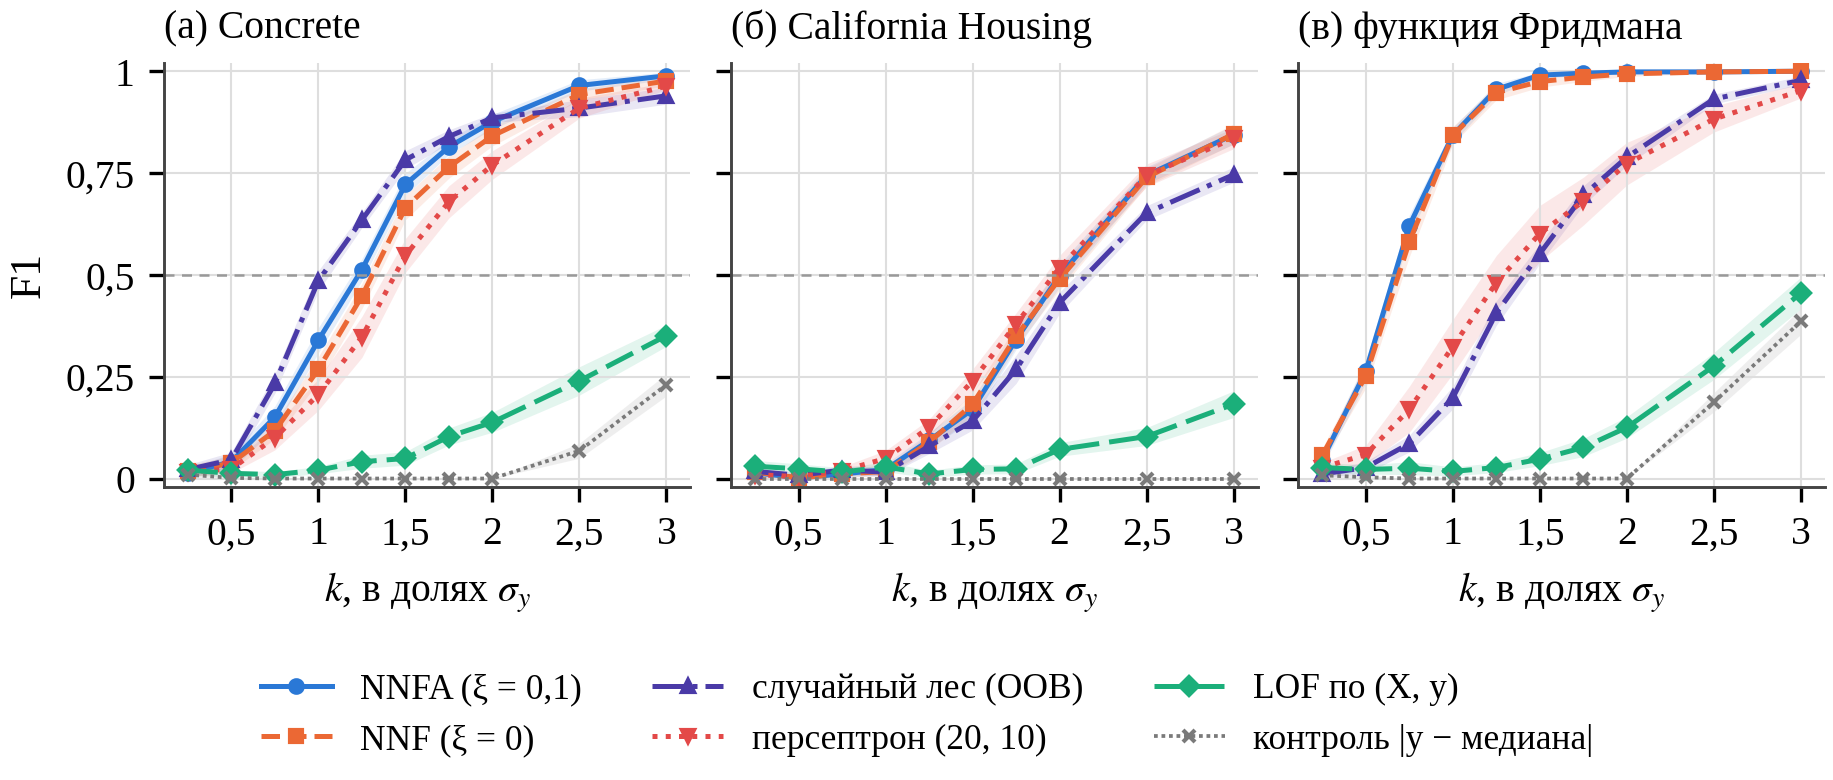

In [13]:
import report_figures as RF                # рисунки отчёта по тем же таблицам
display(Image(str(RF.fig_magnitude3()), width=900))   # рисунок 2

Где NNFA значимо точнее или хуже двух сильнейших конкурентов (критерий Уилкоксона по 30 повторам, поправка
Холма по всем мощностям и обоим конкурентам набора), и контроль протокола: оценка |*y* − медиана| при *k* ≤ 2
не должна находить выбросы.

In [14]:
def significant_k(d, rival):
    rows = []
    for k in K_VALUES:
        a = d[(d.method == NNFA) & (d.k_sigma == k)].set_index("run").f1
        b = d[(d.method == rival) & (d.k_sigma == k)].set_index("run").f1
        p = 1.0 if np.allclose(a - b, 0) else wilcoxon(a, b).pvalue
        rows.append(dict(rival=rival, k=k, diff=(a - b).mean(), p=p))
    return rows


out = {}
for ds in DS:
    t = pd.DataFrame(significant_k(MAG[ds], RF_OOB) + significant_k(MAG[ds], "Neural Network (error)"))
    t["p_holm"] = holm(t.p.tolist())
    for rival, name in [(RF_OOB, "лес OOB"), ("Neural Network (error)", "персептрон")]:
        s = t[(t.rival == rival) & (t.p_holm < 0.05)]
        out[(DS[ds], name)] = {"NNFA точнее при k": ", ".join(c(k) for k in s[s["diff"] > 0].k) or "–",
                               "NNFA хуже при k": ", ".join(c(k) for k in s[s["diff"] < 0].k) or "–"}
display(pd.DataFrame(out).T)
print("контроль |y − медиана|, наибольший F1 при k ≤ 2:",
      {DS[ds]: c(MAG[ds].query("method == @CONTROL and k_sigma <= 2").groupby("k_sigma").f1.mean().max())
       for ds in DS})

NNFA точнее при k               NNFA хуже при k
Concrete   лес OOB                                                     2,50, 3,00  0,75, 1,00, 1,25, 1,50, 1,75
           персептрон              0,75, 1,00, 1,25, 1,50, 1,75, 2,00, 2,50, 3,00                             –
California лес OOB                                         1,75, 2,00, 2,50, 3,00                             –
           персептрон                                                           –                    1,00, 1,50
Фридман    лес OOB     0,25, 0,50, 0,75, 1,00, 1,25, 1,50, 1,75, 2,00, 2,50, 3,00                             –
           персептрон        0,50, 0,75, 1,00, 1,25, 1,50, 1,75, 2,00, 2,50, 3,00                             –

контроль |y − медиана|, наибольший F1 при k ≤ 2: {'Concrete': '0,01', 'California': '0,00', 'Фридман': '0,01'}


## 5. Последовательное удаление выбросов

На каждом шаге ансамбль NNFA обучается на оставшихся *n* наблюдениях, невязка *e*<sub>i</sub> — корень из
среднего по ансамблю квадрата ошибки обучения (в единицах *y*, шкала *y* фиксирована по исходной выборке).
Статистика *z* = max *e*<sub>i</sub> / (1,4826 · med *e*<sub>i</sub>) сравнивается с порогом
λ(*n*) = Φ<sup>−1</sup>(1 − α/(2*n*)), α = 0,05. Наблюдение с наибольшей невязкой удаляется; остановка — три шага
подряд с *z* < λ(*n*) или удалено 10 % выборки. Выбросами объявляются наблюдения, удалённые до последнего шага
с *z* ≥ λ(*n*) включительно.

In [15]:
def critical_value(n, alpha=0.05):
    return float(norm.ppf(1.0 - alpha / (2.0 * n)))          # λ(n), поправка Бонферрони


def robust_max_z(e):
    med = float(np.median(e))
    return float(e.max() / (1.4826 * med)) if med > 0 else np.inf


def nnfa_peel(X, y, xi=0.1, alpha=0.05, patience=3, max_frac=0.10, seed=0, min_steps=0):
    """Возвращает объявленные выбросы и траекторию (порядок удаления, z, λ).
    min_steps — сколько шагов сделать в любом случае для траектории; на решение не влияет."""
    y_range = (float(y.min()), float(y.max()))
    active = np.arange(len(y))
    order, zs, lams = [], [], []
    last_sig, below, stopped = 0, 0, False
    for step in range(1, int(max_frac * len(y)) + 1):
        e = np.sqrt(nnfa_scores(X[active], y[active], xi=xi, seed=seed + step, y_range=y_range, units="original"))
        z, lam = robust_max_z(e), critical_value(len(e), alpha)
        loc = int(np.argmax(e))
        order.append(int(active[loc])); zs.append(z); lams.append(lam)
        if not stopped:
            last_sig, below = (step, 0) if z >= lam else (last_sig, below + 1)
            stopped = below >= patience
        active = np.delete(active, loc)                        # удаляем и обучаем заново
        if stopped and step >= min_steps:
            break
    return order[:last_sig], order, zs, lams


def nnfa_oneshot_threshold(X, y, xi=0.1, alpha=0.05, seed=0):
    """Один шаг с тем же порогом: выбросы — все наблюдения с e_i / (1,4826 · med e) ≥ λ(n)."""
    e = np.sqrt(nnfa_scores(X, y, xi=xi, seed=seed, units="original"))
    return np.flatnonzero(e / (1.4826 * np.median(e)) >= critical_value(len(e), alpha))

In [16]:
def run_peeling(c_, mode, run, ds="concrete"):
    X, y0 = DATA[ds]
    n_out = int(round(c_ * len(y0)))
    rng = np.random.default_rng(777 * run + int(c_ * 1000) + (0 if mode == "isolated" else 5))
    y, truth = inject_y_outliers(y0, n_out, 2.0, rng, mode=mode, X=X)
    seed = 1000 * run
    t0 = time.perf_counter()
    detected, order, zs, lams = nnfa_peel(X, y, seed=seed, min_steps=n_out + 8)
    t_peel = time.perf_counter() - t0
    plans = [("NNFA-peel (автоостановка)", detected, t_peel),
             ("NNFA-порог (один шаг)", nnfa_oneshot_threshold(X, y, seed=seed), np.nan),
             ("NNFA top-k (оракул)", np.flatnonzero(top_k_flags(nnfa_scores(X, y, xi=0.1, seed=seed), n_out)), np.nan)]
    rows = [dict(method=m, n_detected=len(idx), **dict(zip(["precision", "recall", "f1"], prf(idx, truth))),
                 seconds=t, contamination=c_, mode=mode, run=run, n_out=n_out) for m, idx, t in plans]
    traj = [dict(contamination=c_, mode=mode, run=run, n_out=n_out, step=i + 1, z=z, lam=lam,
                 removed_is_outlier=int(truth[j])) for i, (z, lam, j) in enumerate(zip(zs, lams, order))]
    return rows, traj


PEEL, TRAJ = {}, {}
for ds in DS:
    p, t = RES / result_name(ds, "peeling"), RES / result_name(ds, "trajectories")
    if RECOMPUTE or not p.exists():
        jobs = [(c_, m, r, ds) for c_ in [0.01, 0.02, 0.03] for m in ["isolated", "cluster"] for r in range(15)]
        out = Parallel(n_jobs=N_JOBS)(delayed(run_peeling)(*j) for j in jobs)
        pd.DataFrame([x for o, _ in out for x in o]).to_csv(p, index=False)
        pd.DataFrame([x for _, tr in out for x in tr]).to_csv(t, index=False)
    PEEL[ds], TRAJ[ds] = pd.read_csv(p), pd.read_csv(t)

In [17]:
def first_m_share(tr):
    """Доля внесённых выбросов среди первых m удалённых (качество порядка удаления при известном m)."""
    return np.mean([g.sort_values("step").removed_is_outlier.iloc[:g.n_out.iloc[0]].mean()
                    for _, g in tr.groupby("run")])


rows = []
for ds in DS:
    for mode, name in [("isolated", "изолир."), ("cluster", "кластер")]:
        p = PEEL[ds].query("contamination == 0.02 and mode == @mode").groupby("method")
        f1, nd = p.f1.mean(), p.n_detected.mean()
        rows.append({"набор": DS[ds], "выбросы": name,
                     "удаление, автоостановка": c(f1["NNFA-peel (автоостановка)"]),
                     "объявлено / внесено": f"{c(nd['NNFA-peel (автоостановка)'], 1)} / 21",
                     "один шаг, порог λ(n)": c(f1["NNFA-порог (один шаг)"]),
                     "один шаг, топ-m*": c(f1["NNFA top-k (оракул)"]),
                     "первые m удалённых*": c(first_m_share(TRAJ[ds].query("contamination == 0.02 and mode == @mode")))})
pd.DataFrame(rows).set_index(["набор", "выбросы"])    # таблица 3 (* — при известном m)

удаление, автоостановка объявлено / внесено один шаг, порог λ(n) один шаг, топ-m* первые m удалённых*
набор      выбросы                                                                                                      
Concrete   изолир.                    0,91           20,0 / 21                 0,89             0,91                0,91
           кластер                    0,30            5,2 / 21                 0,12             0,51                0,79
California изолир.                    0,50           29,0 / 21                 0,42             0,49                0,49
           кластер                    0,14           16,7 / 21                 0,05             0,19                0,21
Фридман    изолир.                    1,00           21,0 / 21                 0,99             1,00                1,00
           кластер                    1,00           20,9 / 21                 0,75             0,83                1,00

Без внесённых выбросов (исходный набор Concrete, 10 повторов) алгоритм почти ничего не должен удалять.

In [18]:
def run_clean(run):
    X, y = DATA["concrete"]
    t0 = time.perf_counter()
    detected, order, _, _ = nnfa_peel(X, y, seed=5000 + 100 * run)
    return dict(run=run, n_detected=len(detected), n_steps=len(order), seconds=time.perf_counter() - t0)


clean = table("exp2c_clean.csv", [(r,) for r in range(10)], run_clean)
print(f"объявлено выбросами: в среднем {c(clean.n_detected.mean(), 1)}, не более {clean.n_detected.max()} из 1030")

объявлено выбросами: в среднем 1,4, не более 3 из 1030


## 6. Очистка данных и точность итоговой модели

30 разбиений 80/20; в обучающую часть вносится 3 % выбросов мощностью 2σ<sub>y</sub>, тестовая остаётся чистой.
Итоговая модель — персептрон (32, 16), RMSE на тесте усредняется по трём инициализациям.

In [19]:
def final_rmse(Xtr, ytr, Xte, yte, seeds):
    """RMSE итоговой сети на тесте, среднее по начальным инициализациям.
    Строгий критерий останова: при настройках по умолчанию обучение иногда обрывается на плато."""
    sc = StandardScaler().fit(Xtr)
    out = []
    for s in seeds:
        m = MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=3000, tol=1e-7, n_iter_no_change=100, random_state=s)
        m.fit(sc.transform(Xtr), ytr)
        out.append(np.sqrt(np.mean((m.predict(sc.transform(Xte)) - yte) ** 2)))
    return float(np.mean(out))


def run_downstream(split, ds="concrete"):
    X0, y0 = DATA[ds]
    rng = np.random.default_rng(88_000 + split)
    perm = rng.permutation(len(y0))
    te, tr = perm[:int(0.2 * len(y0))], perm[int(0.2 * len(y0)):]
    Xtr, Xte, yte = X0[tr], X0[te], y0[te]
    n_out = int(round(len(tr) * 0.03))
    ytr, truth = inject_y_outliers(y0[tr], n_out, 2.0, rng)
    plans = {"без очистки": [], "идеальная очистка (оракул)": np.flatnonzero(truth),
             "NNFA top-k (оракул k)": np.flatnonzero(top_k_flags(nnfa_scores(Xtr, ytr, xi=0.1, seed=split), n_out)),
             "NNFA-peel (автоостановка)": nnfa_peel(Xtr, ytr, xi=0.1, seed=10 * split)[0]}
    rows = []
    for name, removed in plans.items():
        keep = np.ones(len(ytr), bool)
        keep[removed] = False
        p, r, f = prf(removed, truth)
        rows.append(dict(split=split, strategy=name,
                         rmse=final_rmse(Xtr[keep], ytr[keep], Xte, yte, [100 * split + s for s in range(3)]),
                         n_removed=len(removed), precision=p, recall=r, f1=f))
    return rows


DOWN = {ds: table(result_name(ds, "downstream"), [(s, ds) for s in range(30)], run_downstream) for ds in DS}

In [20]:
STRATS = {"без очистки": "без очистки", "NNFA-peel (автоостановка)": "последовательное удаление",
          "NNFA top-k (оракул k)": "NNFA, топ-m (m известно)", "идеальная очистка (оракул)": "идеальная очистка"}
rmse, extra = {}, {}
for ds in DS:
    w = DOWN[ds].pivot(index="split", columns="strategy", values="rmse")
    base, ideal = w["без очистки"].mean(), w["идеальная очистка (оракул)"].mean()
    p = holm([wilcoxon(w[s], w["без очистки"]).pvalue for s in list(STRATS)[1:]])
    rmse[DS[ds]] = {STRATS[s]: c(w[s].mean()) for s in STRATS}
    for s, ph in zip(list(STRATS)[1:], p):
        # больше 100 %: очистка точнее идеальной, т. е. удаляет и собственные аномалии набора
        extra[(DS[ds], STRATS[s])] = {"доля эффекта идеальной очистки, %": c(100 * (base - w[s].mean()) / (base - ideal), 0),
                                      "p (Холм), сравнение с без очистки": f"{ph:.1e}"}
display(pd.DataFrame(rmse))                         # таблица 4: RMSE на тесте
pd.DataFrame(extra).T

,Concrete,California,Фридман
без очистки,"6,23","0,89","2,39"
последовательное удаление,"5,79","0,79","1,72"
"NNFA, топ-m (m известно)","5,55","0,83","1,71"
идеальная очистка,"5,36","0,86","1,71"


доля эффекта идеальной очистки, % p (Холм), сравнение с без очистки
Concrete   последовательное удаление                                51                           1.7e-06
           NNFA, топ-m (m известно)                                 78                           5.6e-09
           идеальная очистка                                       100                           5.6e-09
California последовательное удаление                               324                           1.4e-07
           NNFA, топ-m (m известно)                                177                           2.8e-06
           идеальная очистка                                       100                           3.8e-04
Фридман    последовательное удаление                                99                           5.6e-09
           NNFA, топ-m (m известно)                                100                           5.6e-09
           идеальная очистка                                       100                           5.6e-09

## 7. Очистка данных и объём обучающей выборки

В каждом из 12 повторов отделяется чистая тестовая часть (206 наблюдений для Concrete, 2000 для California и
функции Фридмана), из остальных данных берутся вложенные обучающие выборки объёма *Q*. В выборку вносится
0, 5, 10 или 20 % выбросов мощностью 2σ<sub>y</sub>, она очищается и на ней обучается персептрон (32, 16).
California берётся из всех 20 433 районов, функция Фридмана генерируется заново в каждом повторе.

Здесь ансамбль NNFA обучается одной матричной операцией (все сети сразу): так расчёт быстрее, а оценки
совпадают с `nnfa_scores` до 1e-9. Кратность — во сколько раз меньший объём нужен после очистки, чтобы
достичь точности, которую без очистки даёт вся выборка (интерполяция по log *Q*).

In [21]:
SIZES = {"Concrete": [100, 140, 200, 280, 400, 570, 824], "California": [150, 250, 400, 650, 1000, 1500],
         "Friedman": [150, 250, 400, 650, 1000, 1500]}
N_TEST = {"Concrete": 206, "California": 2000, "Friedman": 2000}
CONTAMINATIONS = [0.0, 0.05, 0.10, 0.20]


def load_california_full():
    d = pd.read_csv(ROOT / "data" / "housing.csv").dropna(subset=["total_bedrooms"])
    hh = d["households"]
    X = np.column_stack([d["median_income"], d["housing_median_age"], d["total_rooms"] / hh, d["total_bedrooms"] / hh,
                         d["population"], d["population"] / hh, d["latitude"], d["longitude"]]).astype(float)
    X[:, 2:6] = np.log(X[:, 2:6])                  # длинные хвосты: комнаты, спальни, население, заполненность
    X = np.clip(X, np.percentile(X, 0.5, axis=0), np.percentile(X, 99.5, axis=0))
    return X, (d["median_house_value"] / 1e5).to_numpy(float)


FULL = {"Concrete": DATA["concrete"], "California": load_california_full()}


def split(ds, run):
    """Тест и пул обучения повтора run; обучающая выборка объёма Q — первые Q наблюдений пула."""
    rng = np.random.default_rng([{"Concrete": 1, "California": 2, "Friedman": 3}[ds], run])
    if ds == "Friedman":
        X, y = make_friedman1(n_samples=N_TEST[ds] + max(SIZES[ds]), n_features=10, noise=1.0,
                              random_state=int(rng.integers(2**31)))
        return X[:N_TEST[ds]], y[:N_TEST[ds]], X[N_TEST[ds]:], y[N_TEST[ds]:]
    X, y = FULL[ds]
    perm = rng.permutation(len(y))
    te, pool = perm[:N_TEST[ds]], perm[N_TEST[ds]:N_TEST[ds] + max(SIZES[ds])]
    return X[te], y[te], X[pool], y[pool]


def ensemble_errors(Xs, ys, Ns, rng, epochs=500, lr=0.01, b1=0.9, b2=0.999, eps=1e-8):
    """Квадраты ошибок обучения всех сетей ансамбля (строка на сеть); сети обучаются одновременно,
    начальные веса — в том же порядке, что при поочерёдном обучении."""
    n, d = Xs.shape
    K, H = len(Ns), sum(Ns)
    W1, c1 = np.empty((d, H)), np.empty(H)
    W2, c2, mask = np.zeros((H, K)), np.empty(K), np.zeros((H, K))
    off = 0
    for k, N in enumerate(Ns):
        a = 1 / math.sqrt(d)
        W1[:, off:off + N] = rng.uniform(-a, a, (d, N)); c1[off:off + N] = rng.uniform(-a, a, N)
        a = 1 / math.sqrt(N)
        W2[off:off + N, k] = rng.uniform(-a, a, (N, 1)).ravel(); c2[k] = rng.uniform(-a, a, 1)[0]
        mask[off:off + N, k] = 1.0
        off += N
    P = [W1, c1, W2, c2]
    M, V = [np.zeros_like(p) for p in P], [np.zeros_like(p) for p in P]
    Y = ys.reshape(-1, 1)
    for t in range(1, epochs + 1):
        A = np.tanh(Xs @ W1 + c1)
        g = (2.0 / n) * (A @ W2 + c2 - Y)
        gZ = (g @ W2.T) * (1 - A * A)
        G = [Xs.T @ gZ, gZ.sum(0), (A.T @ g) * mask, g.sum(0)]
        k1, k2 = 1 - b1 ** t, 1 - b2 ** t
        for p, gr, m, v in zip(P, G, M, V):
            m *= b1; m += (1 - b1) * gr
            v *= b2; v += (1 - b2) * gr * gr
            p -= lr * (m / k1) / (np.sqrt(v / k2) + eps)
    return ((np.tanh(Xs @ W1 + c1) @ W2 + c2 - Y) ** 2).T


def nnfa_residuals(X, y, seed, y_range=None, xi=0.1):
    """Невязки NNFA в единицах y."""
    lo, hi = (y.min(), y.max()) if y_range is None else y_range
    half = (hi - lo) / 2 if hi > lo else 1.0
    E = ensemble_errors(scale_minus1_1(X), (y - lo) / half - 1, n_range(len(y), X.shape[1], 1, xi),
                        np.random.default_rng(seed))
    return np.sqrt(E.mean(0)) * half


def threshold_flags(e, alpha=0.05):
    return np.flatnonzero(e / (1.4826 * np.median(e)) >= critical_value(len(e), alpha))


def peel(X, y, seed, alpha=0.05, patience=3, max_frac=0.3):
    """Последовательное удаление (раздел 5) на матричном ансамбле; до 30 % выборки."""
    yr = (y.min(), y.max())
    active, order, last_sig, below = np.arange(len(y)), [], 0, 0
    for step in range(1, int(max_frac * len(y)) + 1):
        e = nnfa_residuals(X[active], y[active], seed + step, y_range=yr)
        z = e.max() / (1.4826 * np.median(e))
        loc = int(np.argmax(e))
        order.append(int(active[loc])); active = np.delete(active, loc)
        if z >= critical_value(len(e), alpha):
            last_sig, below = step, 0
        else:
            below += 1
            if below >= patience:
                break
    return np.array(order[:last_sig], int)

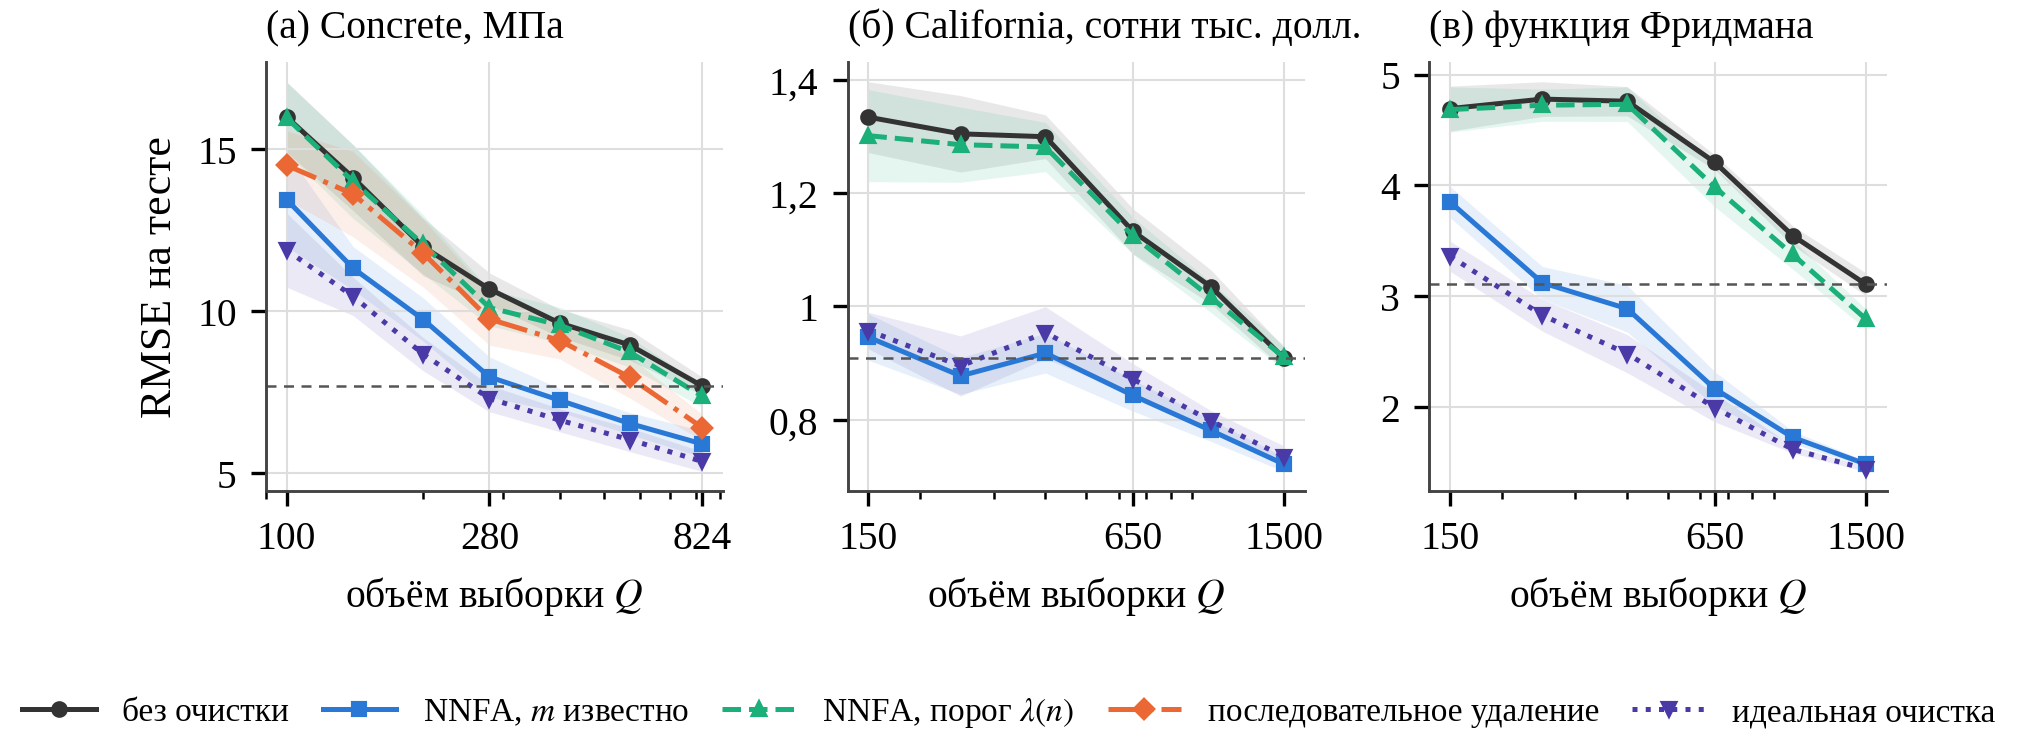

In [22]:
def one_job(ds, c_, run):
    """Один повтор: все объёмы Q, все способы очистки, итоговая модель."""
    Xte, yte, Xp, yp = split(ds, run)
    rows = []
    for Q in SIZES[ds]:
        X, y0 = Xp[:Q], yp[:Q]
        m = int(round(c_ * Q))
        rng = np.random.default_rng([7, run, Q, int(round(c_ * 1000))])
        y, truth = inject_y_outliers(y0, m, 2.0, rng) if m else (y0.copy(), np.zeros(Q, int))
        t0 = time.perf_counter()
        e = nnfa_residuals(X, y, seed=1000 * run + Q)
        plans = {"без очистки": np.array([], int), "NNFA, порог λ(n)": threshold_flags(e)}
        if m:
            plans["NNFA, m известно"] = np.argsort(e)[-m:]
            plans["идеальная очистка"] = np.flatnonzero(truth)
        t_nnfa = time.perf_counter() - t0
        if ds == "Concrete":                       # последовательное удаление — только на Concrete (время)
            t0 = time.perf_counter()
            plans["последовательное удаление"] = peel(X, y, seed=100_000 * (run + 1) + Q)
            t_peel = time.perf_counter() - t0
        for name, removed in plans.items():
            keep = np.ones(Q, bool)
            keep[removed] = False
            rows.append(dict(dataset=ds, contamination=c_, run=run, Q=Q, m=m, strategy=name,
                             rmse=final_rmse(X[keep], y[keep], Xte, yte, [10 * run + s for s in range(2)]),
                             n_removed=len(removed), tp=int(truth[removed].sum()),
                             clean_seconds=t_peel if name == "последовательное удаление" else t_nnfa))
    return rows


ex = table("experiment.csv", [(ds, c_, r) for ds in SIZES for c_ in CONTAMINATIONS for r in range(12)], one_job,
           folder=SS_RES)
display(Image(str(RF.fig_sample_size3(0.10)), width=900))   # рисунок 3: 10 % выбросов

In [23]:
def q_needed(curve, target):
    """Наименьший Q, при котором средний RMSE не выше target (интерполяция по log Q);
    второе значение False — цель достигнута уже в первом узле сетки (точный объём не определён)."""
    curve = curve.dropna()
    q, r = curve.index.to_numpy(float), curve.to_numpy()
    ok = np.flatnonzero(r <= target)
    if not len(ok):
        return np.nan, True
    j = ok[0]
    if j == 0:
        return q[0], False
    w = (r[j - 1] - target) / (r[j - 1] - r[j])
    return float(np.exp(np.log(q[j - 1]) + w * (np.log(q[j]) - np.log(q[j - 1])))), True


def gain(dirty, clean, target):
    """Во сколько раз меньше данных нужно после очистки для точности target: (кратность, нижняя граница)."""
    qd, ed = q_needed(dirty, target)
    qc, ec = q_needed(clean, target)
    if qc != qc or (not ed and not ec):
        return np.nan, False
    return qd / qc, not ec


ORDER = ["NNFA, m известно", "NNFA, порог λ(n)", "последовательное удаление", "идеальная очистка"]
piv = ex.pivot_table(index=["dataset", "contamination", "strategy", "run"], columns="Q", values="rmse")
boot_rng = np.random.default_rng(0)
rows = []
for ds in SIZES:
    qmax = max(SIZES[ds])
    for c_ in CONTAMINATIONS:
        sub = piv.loc[(ds, c_)]
        strats = [s for s in ORDER if s in sub.index.get_level_values(0)]
        dirty = sub.loc["без очистки"].mean()
        runs = sub.loc["без очистки"].index.to_numpy()
        boots = {s: [] for s in strats}
        for _ in range(1000):                       # бутстреп по повторам
            pick = boot_rng.choice(runs, size=len(runs), replace=True)
            db = sub.loc["без очистки"].loc[pick].mean().dropna()
            for s in strats:
                boots[s].append(gain(db, sub.loc[s].loc[pick].mean().dropna(), db[qmax])[0])
        for s in strats:
            g, lower = gain(dirty, sub.loc[s].mean().dropna(), dirty[qmax])
            rows.append(dict(dataset=ds, c=c_, strategy=s, ratio=round(g, 2), lower=lower,
                             lo=round(np.nanpercentile(boots[s], 2.5), 2), hi=round(np.nanpercentile(boots[s], 97.5), 2)))
ratio = pd.DataFrame(rows)


def ratio_cell(r, ci=False):
    if r.ratio != r.ratio:
        return "не достигается"
    if r.lower:
        return "≥ " + c(r.ratio, 1).rstrip("0").rstrip(",")
    return c(r.ratio, 1) + (f" ({c(r.lo, 1)}–{c(r.hi, 1)})" if ci else "")


tab5 = {}
for (ds, c_), g in ratio[ratio.c > 0].groupby(["dataset", "c"], sort=False):
    g = g.set_index("strategy")
    tab5[({"Friedman": "Фридман"}.get(ds, ds), f"{int(c_ * 100)} %")] = {s: ratio_cell(g.loc[s], ci=(s == "NNFA, m известно")) if s in g.index else "–"
                                        for s in ORDER}
pd.DataFrame(tab5).T                                # таблица 5: кратность снижения объёма выборки

NNFA, m известно NNFA, порог λ(n) последовательное удаление идеальная очистка
Concrete   5 %     1,9 (1,7–2,1)              1,3                       1,7               2,1
           10 %    2,6 (2,2–3,1)              1,1                       1,4               3,2
           20 %    2,9 (2,1–3,3)              1,0                       1,0               5,2
California 5 %     2,7 (2,5–3,0)              1,3                         –               2,4
           10 %    7,6 (3,7–9,8)   не достигается                         –               6,7
           20 %             ≥ 10              1,0                         –              ≥ 10
Фридман    5 %     3,6 (3,3–4,0)              2,4                         –               3,7
           10 %    5,9 (4,4–6,6)              1,2                         –               7,9
           20 %    6,8 (5,6–8,3)              1,0                         –              ≥ 10

## 8. Выбросы во входных признаках

Concrete, 2 % наблюдений: 1 или 3 входных признака сдвигаются на 1–4 стандартных отклонения (без
отрицательных дозировок и возраста), *y* не меняется. 15 повторов.

In [24]:
def inject_x_outliers(X, n_out, k_sigma, rng, n_features_hit=1):
    X = np.asarray(X, float).copy()
    idx = rng.choice(len(X), size=n_out, replace=False)
    for i in idx:
        cols = rng.choice(X.shape[1], size=min(n_features_hit, X.shape[1]), replace=False)
        shift = k_sigma * X[:, cols].std(axis=0)
        signs = rng.choice([-1.0, 1.0], size=len(cols))
        signs = np.where(X[i, cols] - shift < 0, 1.0, signs)
        X[i, cols] = X[i, cols] + signs * shift
    truth = np.zeros(len(X), dtype=int)
    truth[idx] = 1
    return X, truth


def run_x_outliers(k, n_hit, run):
    X0, y = DATA["concrete"]
    X, truth = inject_x_outliers(X0, 21, k, np.random.default_rng(31_000 + 97 * run + int(k * 10) + n_hit), n_hit)
    return [dict(k_sigma=k, n_features_hit=n_hit, run=run, method=m, f1=f1, auc=auc)
            for m, f1, auc in score_all(X, y, truth, run, methods=CLASSICAL_METHODS)]


xo = table("exp3a_x_outliers.csv", [(k, h, r) for k in [1.0, 2.0, 3.0, 4.0] for h in [1, 3] for r in range(15)],
           run_x_outliers)
(xo[xo.method.isin([NNF, NNFA, "kNN (pyod)"])]
   .pivot_table(index=["method", "n_features_hit"], columns="k_sigma", values="f1").round(2))

k_sigma                       1.0   2.0   3.0   4.0
method       n_features_hit                        
NNF (ξ=0)    1               0.10  0.20  0.22  0.19
             3               0.27  0.30  0.26  0.22
NNFA (ξ=0,1) 1               0.10  0.20  0.23  0.21
             3               0.26  0.28  0.24  0.17
kNN (pyod)   1               0.05  0.29  0.61  0.90
             3               0.14  0.78  0.95  1.00

## Выводы

1. Перенос кода авторов на NumPy воспроизводит препринт: NNF даёт F1 = 0,755 при опубликованном 0,760, код
   авторов на тех же данных — 0,760; разница меньше стандартной ошибки.
2. NNF и NNFA находят структурные выбросы, которые не видят методы без модели *y*(*X*). Порог обнаружимости
   NNFA — 0,67σ<sub>y</sub> на функции Фридмана, 1,23σ<sub>y</sub> на Concrete и 2,00σ<sub>y</sub> на
   California; он определяется мощностью выброса относительно шума данных. Ни один метод не лучше NNFA на всех
   наборах, но на Concrete порог случайного леса с OOB-ошибкой ниже (1,02σ<sub>y</sub>).
3. Последовательное удаление с автоостановкой без знания числа выбросов работает для изолированных выбросов на
   уровне NNFA с известным *m*, а при низком шуме находит и кластеры. На зашумлённых данных для кластеров
   критерий останавливается слишком рано.
4. Очистка NNFA при известном числе выбросов позволяет получить ту же точность итоговой модели на выборке
   меньшего объёма: примерно в 2–3 раза на Concrete, в 3,6–6,8 раза на функции Фридмана и от 2,7 до 10 и более
   раз на California. Без знания числа выбросов выигрыш заметен только при загрязнении около 5 %.
5. Устойчивость одиночной сети к выбору *N* зависит от алгоритма и длительности обучения (RPROP, 1000 эпох:
   20 % пригодных *N*; Adam: 98 %). Выбросы во входных признаках NNF и NNFA не находят.